In [1]:
import os, sys, re, json, hashlib, random, subprocess, time
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "ijson", "tqdm", "matplotlib", "pandas", "numpy", "huggingface_hub", "tokenizers"], check=False)

import ijson
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED)
print("ready")

ready


In [2]:
WORK = "/kaggle/working"
RAW_DIR = "/kaggle/temp/hf_data"
CORPUS_DIR = os.path.join(WORK, "corpus")
os.makedirs(RAW_DIR, exist_ok=True)
os.makedirs(CORPUS_DIR, exist_ok=True)
print("WORK:", WORK)

WORK: /kaggle/working


In [3]:
from huggingface_hub import login, snapshot_download
from kaggle_secrets import UserSecretsClient
login(token=UserSecretsClient().get_secret("HF_TOKEN"))
snapshot_download(repo_id="Exploration-Lab/CS-781-Capstone", repo_type="dataset",
                  local_dir=RAW_DIR, allow_patterns=["Phase_1_Pretraining/*"])
for dp, _, fns in os.walk(RAW_DIR):
    for fn in fns:
        p = os.path.join(dp, fn)
        print(f"{os.path.getsize(p)/1e9:7.2f} GB  {p}")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

  10.67 GB  /kaggle/temp/hf_data/Phase_1_Pretraining/Train/train_high_courts.json
   1.32 GB  /kaggle/temp/hf_data/Phase_1_Pretraining/Train/train_supreme_court.json
   6.48 GB  /kaggle/temp/hf_data/Phase_1_Pretraining/Train/train_tribunals.json
   0.73 GB  /kaggle/temp/hf_data/Phase_1_Pretraining/Train/train_acts.json
   0.00 GB  /kaggle/temp/hf_data/Phase_1_Pretraining/Test/test.json
   0.00 GB  /kaggle/temp/hf_data/.cache/huggingface/CACHEDIR.TAG
   0.00 GB  /kaggle/temp/hf_data/.cache/huggingface/.gitignore
   0.00 GB  /kaggle/temp/hf_data/.cache/huggingface/download/Phase_1_Pretraining/Train/train_high_courts.json.lock
   0.00 GB  /kaggle/temp/hf_data/.cache/huggingface/download/Phase_1_Pretraining/Train/train_supreme_court.json.lock
   0.00 GB  /kaggle/temp/hf_data/.cache/huggingface/download/Phase_1_Pretraining/Train/train_supreme_court.json.metadata
   0.00 GB  /kaggle/temp/hf_data/.cache/huggingface/download/Phase_1_Pretraining/Train/train_tribunals.json.lock
   0.00 GB  /kagg

In [4]:
TRAIN_DIR = "/kaggle/temp/hf_data/Phase_1_Pretraining/Train"
TEST_PATH = "/kaggle/temp/hf_data/Phase_1_Pretraining/Test/test.json"

PATHS = {
    "acts":          os.path.join(TRAIN_DIR, "train_acts.json"),
    "high_courts":   os.path.join(TRAIN_DIR, "train_high_courts.json"),
    "supreme_court": os.path.join(TRAIN_DIR, "train_supreme_court.json"),
    "tribunals":     os.path.join(TRAIN_DIR, "train_tribunals.json"),
}
for k, v in PATHS.items():
    print(f"{k:14s} ->", v, "| exists:", os.path.exists(v))
print("test           ->", TEST_PATH, "| exists:", os.path.exists(TEST_PATH))
assert all(os.path.exists(v) for v in PATHS.values())
assert os.path.exists(TEST_PATH)

acts           -> /kaggle/temp/hf_data/Phase_1_Pretraining/Train/train_acts.json | exists: True
high_courts    -> /kaggle/temp/hf_data/Phase_1_Pretraining/Train/train_high_courts.json | exists: True
supreme_court  -> /kaggle/temp/hf_data/Phase_1_Pretraining/Train/train_supreme_court.json | exists: True
tribunals      -> /kaggle/temp/hf_data/Phase_1_Pretraining/Train/train_tribunals.json | exists: True
test           -> /kaggle/temp/hf_data/Phase_1_Pretraining/Test/test.json | exists: True


In [5]:
def _first_nonspace_char(path):
    with open(path, "rb") as f:
        while True:
            c = f.read(1)
            if not c: return None
            if not c.isspace(): return c.decode("utf-8", "ignore")

def _extract_text(v):
    if isinstance(v, str): return v
    if isinstance(v, dict):
        for k in ("text", "content", "judgment", "body", "document"):
            if isinstance(v.get(k), str): return v[k]
        strs = [x for x in v.values() if isinstance(x, str)]
        return max(strs, key=len) if strs else None
    return None

def _looks_like_jsonl(path):
    size = os.path.getsize(path)
    with open(path, "rb") as f:
        line = f.readline()
    try:
        json.loads(line)
        return len(line) + 4 < size
    except Exception:
        return False

def iter_docs(path):
    if _looks_like_jsonl(path):
        with open(path, "r", encoding="utf-8") as f:
            for line in f:
                line = line.strip()
                if not line: continue
                t = _extract_text(json.loads(line))
                if t: yield t
        return
    fc = _first_nonspace_char(path)
    with open(path, "rb") as f:
        if fc == "[":
            for item in ijson.items(f, "item"):
                t = _extract_text(item)
                if t: yield t
        elif fc == "{":
            for _, v in ijson.kvitems(f, ""):
                if isinstance(v, list):
                    for it in v:
                        t = _extract_text(it)
                        if t: yield t
                else:
                    t = _extract_text(v)
                    if t: yield t
        else:
            raise ValueError(f"Unrecognised JSON layout in {path}")
print("reader defined")

reader defined


In [6]:
for k, p in PATHS.items():
    with open(p, "rb") as f:
        head = f.read(300).decode("utf-8", "ignore")
    print(f"\n=== {k}  ({os.path.getsize(p)/1e9:.2f} GB) ===")
    print(head.replace("\n", " ")[:300])


=== acts  (0.73 GB) ===
[ {"title": "Bangalore City Planning Area Zonal Regulations (Amendment and Validation) Act, 1996", "category": "Greater Bengaluru City Corporation - Act", "year": 1972, "url": "https://indiankanoon.org/doc/179573747/", "text": "Bangalore City Planning Area Zonal Regulations (Amendment and Validation

=== high_courts  (10.67 GB) ===
[ {"court": "Allahabad High Court", "court_id": "9~13", "year": "1987", "bench": "cishclko", "filepath": "/legal-nlp/RAW_DATA/High_courts/pdf/1987/court=9_13/bench=cishclko/UPHC020003871986_1_2023-08-10.pdf", "page_count": 1, "word_count": 175, "char_count": 1040, "text": "Court No. - 24 Case :- SEC

=== supreme_court  (1.32 GB) ===
[ {"title": "His Holiness Sri Vishwothama Thirtha ... vs The State Of Mysore", "date": "1961-12-18", "court": "Supreme Court of India", "citations": "AIR 1966 SUPREME COURT 1882, 1962 2 SCJ 131", "bench": "", "headnote": "The shrine in suit which was originally founded by Shri Madhavacharya, a Hindu

=== 

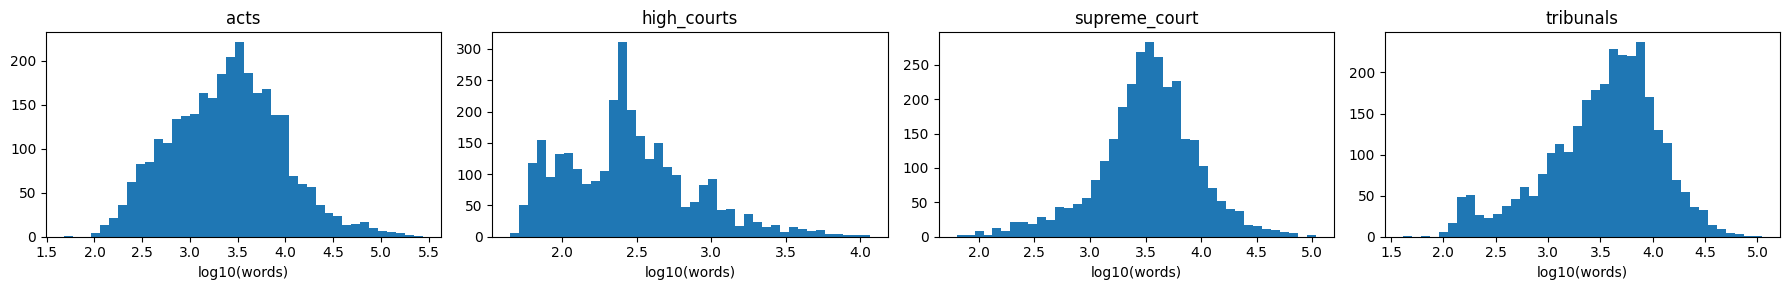

       source  docs  mean_words  median   p10     p90    max  frac_ge_640
         acts  3000      6304.7  2544.5 415.0 12375.4 277710          0.8
  high_courts  3000       503.2   258.0  75.0  1001.0  11511          0.2
supreme_court  3000      5442.2  3435.5 918.5 10912.6 107742          0.9
    tribunals  3000      6043.2  4011.5 560.9 13345.7 110524          0.9

--- acts sample ---
Bangalore City Planning Area Zonal Regulations (Amendment and Validation) Act, 1996 (Karnataka Act No. 2 of 1996) Statements of objects and Reasons - Act 2 of 1996. - The Bangalore City Planning Area Zonal Regulations 1972, which was in vogue till 1984, provided for construction of five floors including ground floor. The Corporation of the City of Bangalore granted permission for construction of buildings beyond five floors in certain cases. In respect of some of the buildings the permission granted by the Corporation contrary to the Zonal Regulations then in force was questioned in the High C

--- hig

In [7]:
N_SAMPLE = 3000
rows, samples = [], {}
fig, axes = plt.subplots(1, 4, figsize=(18, 3))
for ax, (k, p) in zip(axes, PATHS.items()):
    lens, keep = [], []
    for i, t in enumerate(iter_docs(p)):
        lens.append(len(t.split()))
        if i < 2: keep.append(t[:600])
        if i + 1 >= N_SAMPLE: break
    samples[k] = keep
    lens = np.array(lens)
    rows.append(dict(source=k, docs=len(lens), mean_words=lens.mean(),
                     median=np.median(lens), p10=np.percentile(lens, 10),
                     p90=np.percentile(lens, 90), max=lens.max(),
                     frac_ge_640=(lens >= 640).mean()))
    ax.hist(np.log10(lens + 1), bins=40)
    ax.set_title(k); ax.set_xlabel("log10(words)")
plt.tight_layout()
plt.savefig(os.path.join(WORK, "doc_length_hist.png"), dpi=120)
plt.show()
print(pd.DataFrame(rows).round(1).to_string(index=False))
for k, v in samples.items():
    print(f"\n--- {k} sample ---\n{v[0] if v else ''}")

In [8]:
_ws = re.compile(r"[ \t\u00a0\u200b]+")
_nl = re.compile(r"\n{3,}")

def clean_text(t):
    t = t.replace("\r\n", "\n").replace("\r", "\n")
    t = _ws.sub(" ", t)
    t = re.sub(r" ?\n ?", "\n", t)
    t = _nl.sub("\n\n", t)
    return t.strip()

def doc_hash(t):
    return int(hashlib.md5(t.encode("utf-8", "ignore")).hexdigest()[:16], 16)

def is_val(h, permille):
    return (h % 1000) < permille
print("helpers defined")

helpers defined


In [9]:
MIX = {
    "acts":          dict(keep_prob=1.0, max_words=30_000_000),
    "high_courts":   dict(keep_prob=0.5, max_words=60_000_000),
    "supreme_court": dict(keep_prob=1.0, max_words=50_000_000),
    "tribunals":     dict(keep_prob=0.5, max_words=30_000_000),
}
MIN_WORDS = 50
VAL_PERMILLE = 5
MAX_VAL_WORDS_PER_SRC = 1_500_000

In [10]:
def build_corpus(mix=MIX, out_dir=CORPUS_DIR):
    seen, stats = set(), {}
    rng = random.Random(SEED)
    for src, cfg in mix.items():
        t0 = time.time()
        ftr = open(os.path.join(out_dir, f"train_{src}.jsonl"), "w", encoding="utf-8")
        fva = open(os.path.join(out_dir, f"val_{src}.jsonl"), "w", encoding="utf-8")
        s = dict(read=0, dup=0, short=0, train_docs=0, val_docs=0, train_words=0, val_words=0)
        for raw in tqdm(iter_docs(PATHS[src]), desc=src):
            s["read"] += 1
            t = clean_text(raw)
            n = len(t.split())
            if n < MIN_WORDS:
                s["short"] += 1; continue
            h = doc_hash(t)
            if h in seen:
                s["dup"] += 1; continue
            seen.add(h)
            if is_val(h, VAL_PERMILLE):
                if s["val_words"] < MAX_VAL_WORDS_PER_SRC:
                    fva.write(json.dumps({"src": src, "text": t}) + "\n")
                    s["val_docs"] += 1; s["val_words"] += n
                continue
            if rng.random() > cfg["keep_prob"]: continue
            if cfg["max_words"] and s["train_words"] >= cfg["max_words"]: continue
            ftr.write(json.dumps({"src": src, "text": t}) + "\n")
            s["train_docs"] += 1; s["train_words"] += n
        ftr.close(); fva.close()
        s["seconds"] = round(time.time() - t0, 1)
        stats[src] = s
        print(src, s)
    with open(os.path.join(out_dir, "corpus_stats.json"), "w") as f:
        json.dump(dict(mix=mix, stats=stats), f, indent=2)
    return stats

CORPUS_STATS = build_corpus()
tot = sum(v["train_words"] for v in CORPUS_STATS.values())
print(f"\nTotal train words: {tot:,}  (~{int(tot/0.7):,} tokens est.)")

acts: 0it [00:00, ?it/s]

acts {'read': 18822, 'dup': 90, 'short': 5, 'train_docs': 4958, 'val_docs': 78, 'train_words': 30003072, 'val_words': 490245, 'seconds': 73.9}


high_courts: 0it [00:00, ?it/s]

high_courts {'read': 2536738, 'dup': 115596, 'short': 75154, 'train_docs': 141757, 'val_docs': 3335, 'train_words': 60000691, 'val_words': 1500806, 'seconds': 989.8}


supreme_court: 0it [00:00, ?it/s]

supreme_court {'read': 55528, 'dup': 154, 'short': 87, 'train_docs': 12523, 'val_docs': 274, 'train_words': 50000237, 'val_words': 1133759, 'seconds': 124.5}


tribunals: 0it [00:00, ?it/s]

tribunals {'read': 869132, 'dup': 4796, 'short': 3248, 'train_docs': 15026, 'val_docs': 1623, 'train_words': 30001189, 'val_words': 1500067, 'seconds': 605.5}

Total train words: 170,005,189  (~242,864,555 tokens est.)


In [11]:
PROMPT_WORDS, GEN_WORDS, N_VAL_PROMPTS = 512, 128, 300

def build_val_prompts(n=N_VAL_PROMPTS, out_dir=CORPUS_DIR):
    rng = random.Random(SEED)
    pool = []
    for src in MIX:
        with open(os.path.join(out_dir, f"val_{src}.jsonl"), encoding="utf-8") as f:
            for line in f:
                d = json.loads(line)
                if len(d["text"].split()) >= PROMPT_WORDS + GEN_WORDS:
                    pool.append(d)
    rng.shuffle(pool)
    prompts, refs = {}, {}
    for i, d in enumerate(pool[:n], 1):
        w = d["text"].split()
        start = 0 if rng.random() < 0.5 else rng.randint(0, len(w) - PROMPT_WORDS - GEN_WORDS)
        prompts[str(i)] = {"text": " ".join(w[start:start + PROMPT_WORDS])}
        refs[str(i)] = {"text": " ".join(w[start + PROMPT_WORDS:start + PROMPT_WORDS + GEN_WORDS])}
    json.dump(prompts, open(os.path.join(out_dir, "val_prompts.json"), "w"))
    json.dump(refs, open(os.path.join(out_dir, "val_refs.json"), "w"))
    print(f"Saved {len(prompts)} validation prompts")
    return prompts, refs

VAL_PROMPTS, VAL_REFS = build_val_prompts()

Saved 300 validation prompts


In [12]:
test_data = json.load(open(TEST_PATH, encoding="utf-8"))
print("num test prompts:", len(test_data))
tw = [len(v["text"].split()) for v in test_data.values()]
print("prompt words min/mean/max:", min(tw), round(float(np.mean(tw)), 1), max(tw))
k0 = next(iter(test_data))
print("first key:", k0, "|", test_data[k0]["text"][:200], "...")

num test prompts: 1000
prompt words min/mean/max: 512 512.0 512
first key: 1 | The issue involved in these petitions is as to whether the acquisition proceedings can be challenged at a belated stage. The issue is no more res integra as the issue has been considered by this Court ...


In [13]:
for fn in sorted(os.listdir(CORPUS_DIR)):
    print(f"{fn:35s} {os.path.getsize(os.path.join(CORPUS_DIR, fn))/1e6:9.1f} MB")

corpus_stats.json                         0.0 MB
train_acts.jsonl                        181.5 MB
train_high_courts.jsonl                 370.0 MB
train_supreme_court.jsonl               296.8 MB
train_tribunals.jsonl                   184.3 MB
val_acts.jsonl                            3.0 MB
val_high_courts.jsonl                     9.3 MB
val_prompts.json                          0.9 MB
val_refs.json                             0.2 MB
val_supreme_court.jsonl                   6.8 MB
val_tribunals.jsonl                       9.6 MB


In [14]:
#section2

In [15]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

TOK_DIR = os.path.join(WORK, "tokenizers")
BIN_DIR = os.path.join(WORK, "bins")
os.makedirs(TOK_DIR, exist_ok=True)
os.makedirs(BIN_DIR, exist_ok=True)

SRCS = ["acts", "high_courts", "supreme_court", "tribunals"]
print(os.listdir(CORPUS_DIR))

['train_high_courts.jsonl', 'val_refs.json', 'val_tribunals.jsonl', 'train_tribunals.jsonl', 'train_supreme_court.jsonl', 'val_prompts.json', 'val_high_courts.jsonl', 'corpus_stats.json', 'val_acts.jsonl', 'train_acts.jsonl', 'val_supreme_court.jsonl']


In [16]:
VOCAB_SIZE = 32000
TAG = f"bpe{VOCAB_SIZE//1000}k"
SPECIAL = ["<pad>", "<unk>", "<bos>", "<eos>"]
TOK_TRAIN_WORDS_PER_SRC = 8_000_000
TOK_PATH = os.path.join(TOK_DIR, f"{TAG}.json")
print(TAG, TOK_PATH)

bpe32k /kaggle/working/tokenizers/bpe32k.json


In [17]:
def iter_jsonl(path):
    with open(path, encoding="utf-8") as f:
        for line in f:
            yield json.loads(line)["text"]

def tok_train_iter():
    for src in SRCS:
        words = 0
        for t in iter_jsonl(os.path.join(CORPUS_DIR, f"train_{src}.jsonl")):
            yield t
            words += len(t.split())
            if words >= TOK_TRAIN_WORDS_PER_SRC:
                break
print("iterator ready")

iterator ready


In [18]:
if os.path.exists(TOK_PATH):
    tok = Tokenizer.from_file(TOK_PATH)
    print("loaded existing", TOK_PATH)
else:
    tok = Tokenizer(models.BPE(unk_token="<unk>"))
    tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tok.decoder = decoders.ByteLevel()
    trainer = trainers.BpeTrainer(
        vocab_size=VOCAB_SIZE,
        special_tokens=SPECIAL,
        initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
        min_frequency=2,
        show_progress=True,
    )
    t0 = time.time()
    tok.train_from_iterator(tok_train_iter(), trainer=trainer)
    tok.save(TOK_PATH)
    print(f"trained in {time.time()-t0:.0f}s ->", TOK_PATH)

PAD_ID, UNK_ID, BOS_ID, EOS_ID = [tok.token_to_id(s) for s in SPECIAL]
print("vocab:", tok.get_vocab_size(), "| ids:", PAD_ID, UNK_ID, BOS_ID, EOS_ID)




trained in 30s -> /kaggle/working/tokenizers/bpe32k.json
vocab: 32000 | ids: 0 1 2 3


In [19]:
sample = next(iter_jsonl(os.path.join(CORPUS_DIR, "val_supreme_court.jsonl")))[:500]
ids = tok.encode(sample).ids
print("round-trip OK:", tok.decode(ids) == sample, "| tokens:", len(ids))

def fertility(src, n=300):
    tw = tt = 0
    for i, t in enumerate(iter_jsonl(os.path.join(CORPUS_DIR, f"val_{src}.jsonl"))):
        tw += len(t.split()); tt += len(tok.encode(t).ids)
        if i + 1 >= n: break
    return tt / max(tw, 1)

FERT = {s: round(fertility(s), 3) for s in SRCS}
print("tokens/word:", FERT)

vp = json.load(open(os.path.join(CORPUS_DIR, "val_prompts.json")))
lens = [len(tok.encode(v["text"]).ids) for v in list(vp.values())[:100]]
print("512-word prompt -> tokens min/mean/max:", min(lens), round(np.mean(lens)), max(lens))

round-trip OK: True | tokens: 152
tokens/word: {'acts': 1.295, 'high_courts': 1.296, 'supreme_court': 1.24, 'tribunals': 1.407}
512-word prompt -> tokens min/mean/max: 556 713 1552


In [20]:
EXPECTED_FERT = {'acts': 1.295, 'high_courts': 1.296, 'supreme_court': 1.24, 'tribunals': 1.407}
ok = (len(ids) == 152 and FERT == EXPECTED_FERT and min(lens) == 556
      and round(float(np.mean(lens))) == 713 and max(lens) == 1552)
print("tokenizer matches original run:", ok)
assert ok, "Tokenizer differs. Stop and send me the cell 18 output."

tokenizer matches original run: True


In [21]:
def tokenize_split(split, batch=512, flush_tokens=20_000_000):
    out_path = os.path.join(BIN_DIR, f"{TAG}_{split}.bin")
    total, buf = 0, []
    with open(out_path, "wb") as fout:
        def flush():
            nonlocal buf, total
            if buf:
                arr = np.concatenate(buf).astype(np.uint16)
                fout.write(arr.tobytes()); total += len(arr); buf = []
        for src in SRCS:
            path = os.path.join(CORPUS_DIR, f"{split}_{src}.jsonl")
            docs, held = [], 0
            for t in tqdm(iter_jsonl(path), desc=f"{split}/{src}"):
                docs.append(t)
                if len(docs) == batch:
                    for e in tok.encode_batch(docs):
                        buf.append(np.array(e.ids + [EOS_ID], dtype=np.uint16)); held += len(e.ids) + 1
                    docs = []
                    if held >= flush_tokens: flush(); held = 0
            if docs:
                for e in tok.encode_batch(docs):
                    buf.append(np.array(e.ids + [EOS_ID], dtype=np.uint16))
            flush()
    print(f"{split}: {total:,} tokens -> {out_path}")
    return total

N_TOK = {}
N_TOK["val"]   = tokenize_split("val")
N_TOK["train"] = tokenize_split("train")
json.dump(dict(tag=TAG, vocab=VOCAB_SIZE, eos=EOS_ID, pad=PAD_ID, n_tokens=N_TOK, fertility=FERT),
          open(os.path.join(BIN_DIR, f"{TAG}_meta.json"), "w"), indent=2)

val/acts: 0it [00:00, ?it/s]

val/high_courts: 0it [00:00, ?it/s]

val/supreme_court: 0it [00:00, ?it/s]

val/tribunals: 0it [00:00, ?it/s]

val: 6,499,451 tokens -> /kaggle/working/bins/bpe32k_val.bin


train/acts: 0it [00:00, ?it/s]

train/high_courts: 0it [00:00, ?it/s]

train/supreme_court: 0it [00:00, ?it/s]

train/tribunals: 0it [00:00, ?it/s]

train: 222,512,359 tokens -> /kaggle/working/bins/bpe32k_train.bin


In [22]:
tr = np.memmap(os.path.join(BIN_DIR, f"{TAG}_train.bin"), dtype=np.uint16, mode="r")
va = np.memmap(os.path.join(BIN_DIR, f"{TAG}_val.bin"),   dtype=np.uint16, mode="r")
print("train tokens:", len(tr), "| val tokens:", len(va), "| max id:", int(tr[:5_000_000].max()))
print("eos count in first 5M:", int((tr[:5_000_000] == EOS_ID).sum()))
print(tok.decode(tr[:120].tolist()))

train tokens: 222512359 | val tokens: 6499451 | max id: 31998
eos count in first 5M: 543
Bangalore City Planning Area Zonal Regulations (Amendment and Validation) Act, 1996 (Karnataka Act No. 2 of 1996) Statements of objects and Reasons - Act 2 of 1996. - The Bangalore City Planning Area Zonal Regulations 1972, which was in vogue till 1984, provided for construction of five floors including ground floor. The Corporation of the City of Bangalore granted permission for construction of buildings beyond five floors in certain cases. In respect of some of the buildings the permission granted by the Corporation contrary to the Zonal Regulations then in force was questioned in the High Court and the Division Bench of the High Court held that the


In [23]:
#section3

In [24]:
import torch
import torch.nn as nn
import torch.nn.functional as F


In [25]:
with open(os.path.join(BIN_DIR, f"{TAG}_meta.json")) as f:
    META = json.load(f)
VOCAB_SIZE, PAD_ID, EOS_ID = META["vocab"], META["pad"], META["eos"]

In [26]:
class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(dim))
        self.eps = eps
    def forward(self, x):
        norm = x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)
        return norm * self.weight

def rotary_freqs(dim, max_seq, base=10000.0, device="cpu"):
    inv_freq = 1.0 / (base ** (torch.arange(0, dim, 2, device=device).float() / dim))
    t = torch.arange(max_seq, device=device).float()
    freqs = torch.outer(t, inv_freq)
    return torch.cos(freqs), torch.sin(freqs)

def apply_rotary(x, cos, sin):
    d = x.shape[-1]
    x1, x2 = x[..., :d // 2], x[..., d // 2:]
    cos = cos[:x.shape[-2], :d // 2].unsqueeze(0).unsqueeze(0)
    sin = sin[:x.shape[-2], :d // 2].unsqueeze(0).unsqueeze(0)
    rx1 = x1 * cos - x2 * sin
    rx2 = x2 * cos + x1 * sin
    return torch.cat([rx1, rx2], dim=-1)

class SwiGLU(nn.Module):
    def __init__(self, dim, hidden):
        super().__init__()
        self.w1 = nn.Linear(dim, hidden, bias=False)
        self.w2 = nn.Linear(dim, hidden, bias=False)
        self.w3 = nn.Linear(hidden, dim, bias=False)
    def forward(self, x):
        return self.w3(F.silu(self.w1(x)) * self.w2(x))
print("blocks defined")

blocks defined


In [27]:
class CausalSelfAttention(nn.Module):
    def __init__(self, dim, n_heads, max_seq):
        super().__init__()
        self.n_heads, self.hd = n_heads, dim // n_heads
        self.qkv = nn.Linear(dim, 3 * dim, bias=False)
        self.proj = nn.Linear(dim, dim, bias=False)
        cos, sin = rotary_freqs(self.hd, max_seq)
        self.register_buffer("cos", cos, persistent=False)
        self.register_buffer("sin", sin, persistent=False)
    def forward(self, x):
        B, T, C = x.shape
        qkv = self.qkv(x).view(B, T, 3, self.n_heads, self.hd).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        q, k = apply_rotary(q, self.cos, self.sin), apply_rotary(k, self.cos, self.sin)
        out = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        out = out.transpose(1, 2).reshape(B, T, C)
        return self.proj(out)

class DecoderBlock(nn.Module):
    def __init__(self, dim, n_heads, max_seq, mlp_mult=4):
        super().__init__()
        self.norm1 = RMSNorm(dim)
        self.attn = CausalSelfAttention(dim, n_heads, max_seq)
        self.norm2 = RMSNorm(dim)
        self.mlp = SwiGLU(dim, int(dim * mlp_mult * 2 / 3))
    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        x = x + self.mlp(self.norm2(x))
        return x

class DecoderOnlyLM(nn.Module):
    def __init__(self, vocab=VOCAB_SIZE, dim=768, n_layers=12, n_heads=12, max_seq=2048):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab, dim)
        self.blocks = nn.ModuleList([DecoderBlock(dim, n_heads, max_seq) for _ in range(n_layers)])
        self.norm_f = RMSNorm(dim)
        self.head = nn.Linear(dim, vocab, bias=False)
        self.head.weight = self.tok_emb.weight
        self.max_seq = max_seq
    def forward(self, idx, targets=None):
        x = self.tok_emb(idx)
        for b in self.blocks:
            x = b(x)
        x = self.norm_f(x)
        logits = self.head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1), ignore_index=PAD_ID)
        return logits, loss

def count_params(m):
    return sum(p.numel() for p in m.parameters())

m = DecoderOnlyLM(dim=768, n_layers=12, n_heads=12)
print("DecoderOnlyLM params:", f"{count_params(m)/1e6:.1f}M")
del m

DecoderOnlyLM params: 109.5M


In [28]:
class Attn(nn.Module):
    def __init__(self, dim, n_heads, max_seq, n_kv_heads=None, causal=True, window=None, rope=True):
        super().__init__()
        self.h, self.kv = n_heads, (n_kv_heads or n_heads)
        self.hd = dim // n_heads
        self.causal, self.window, self.rope = causal, window, rope
        self.q = nn.Linear(dim, self.h * self.hd, bias=False)
        self.k = nn.Linear(dim, self.kv * self.hd, bias=False)
        self.v = nn.Linear(dim, self.kv * self.hd, bias=False)
        self.proj = nn.Linear(self.h * self.hd, dim, bias=False)
        if rope:
            cos, sin = rotary_freqs(self.hd, max_seq)
            self.register_buffer("cos", cos, persistent=False)
            self.register_buffer("sin", sin, persistent=False)

    def _mask(self, T, device):
        i = torch.arange(T, device=device)[:, None]
        j = torch.arange(T, device=device)[None, :]
        return (j <= i) & (i - j < self.window)

    def forward(self, x, ctx=None):
        B, T, C = x.shape
        src = x if ctx is None else ctx
        S = src.size(1)
        q = self.q(x).view(B, T, self.h, self.hd).transpose(1, 2)
        k = self.k(src).view(B, S, self.kv, self.hd).transpose(1, 2)
        v = self.v(src).view(B, S, self.kv, self.hd).transpose(1, 2)
        if self.rope and ctx is None:
            q, k = apply_rotary(q, self.cos, self.sin), apply_rotary(k, self.cos, self.sin)
        if self.kv != self.h:
            r = self.h // self.kv
            k, v = k.repeat_interleave(r, dim=1), v.repeat_interleave(r, dim=1)
        if ctx is None and self.causal and self.window:
            out = F.scaled_dot_product_attention(q, k, v, attn_mask=self._mask(T, x.device))
        else:
            out = F.scaled_dot_product_attention(q, k, v, is_causal=(self.causal and ctx is None))
        return self.proj(out.transpose(1, 2).reshape(B, T, self.h * self.hd))
print("Attn defined")

Attn defined


In [29]:
class EncBlock(nn.Module):
    def __init__(self, dim, nh, ms, mlp_mult=4):
        super().__init__()
        self.n1, self.attn = RMSNorm(dim), Attn(dim, nh, ms, causal=False)
        self.n2, self.mlp = RMSNorm(dim), SwiGLU(dim, int(dim * mlp_mult * 2 / 3))
    def forward(self, x):
        x = x + self.attn(self.n1(x))
        return x + self.mlp(self.n2(x))

class CrossDecBlock(nn.Module):
    def __init__(self, dim, nh, ms, mlp_mult=4):
        super().__init__()
        self.n1, self.self_attn = RMSNorm(dim), Attn(dim, nh, ms, causal=True)
        self.n2, self.cross = RMSNorm(dim), Attn(dim, nh, ms, causal=False, rope=False)
        self.n3, self.mlp = RMSNorm(dim), SwiGLU(dim, int(dim * mlp_mult * 2 / 3))
    def forward(self, x, enc):
        x = x + self.self_attn(self.n1(x))
        x = x + self.cross(self.n2(x), ctx=enc)
        return x + self.mlp(self.n3(x))

class EncoderDecoderLM(nn.Module):
    """Same call as the decoder-only model: forward(idx, targets).
    Encoder sees idx[:, :split]; decoder predicts idx[:, split:]."""
    def __init__(self, vocab=VOCAB_SIZE, dim=768, n_enc=6, n_dec=6, n_heads=12, max_seq=2048):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab, dim)
        self.enc = nn.ModuleList([EncBlock(dim, n_heads, max_seq) for _ in range(n_enc)])
        self.dec = nn.ModuleList([CrossDecBlock(dim, n_heads, max_seq) for _ in range(n_dec)])
        self.norm_e, self.norm_f = RMSNorm(dim), RMSNorm(dim)
        self.head = nn.Linear(dim, vocab, bias=False)
        self.head.weight = self.tok_emb.weight
        self.max_seq = max_seq
    def encode(self, src):
        e = self.tok_emb(src)
        for b in self.enc: e = b(e)
        return self.norm_e(e)
    def decode(self, dec_in, enc_out):
        x = self.tok_emb(dec_in)
        for b in self.dec: x = b(x, enc_out)
        return self.head(self.norm_f(x))
    def forward(self, idx, targets=None, split=None):
        T = idx.size(1)
        split = split or T // 2
        enc_out = self.encode(idx[:, :split])
        logits = self.decode(idx[:, split - 1:], enc_out)     # decoder starts from last prompt token
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)),
                                   targets[:, split - 1:].reshape(-1), ignore_index=PAD_ID)
        return logits, loss
print("EncoderDecoderLM defined")

EncoderDecoderLM defined


In [30]:
class GatedLinearRecurrence(nn.Module):
    """h_t = a_t * h_{t-1} + i_t * u_t, computed in parallel by chunks (linear time)."""
    def __init__(self, dim, chunk=64):
        super().__init__()
        self.inp = nn.Linear(dim, 4 * dim, bias=False)
        self.conv = nn.Conv1d(dim, dim, 4, groups=dim, padding=3)
        self.out = nn.Linear(dim, dim, bias=False)
        self.chunk = chunk
    def _scan(self, log_a, z):
        B, T, C = z.shape
        L = self.chunk
        pad = (-T) % L
        if pad:
            log_a, z = F.pad(log_a, (0, 0, 0, pad)), F.pad(z, (0, 0, 0, pad))
        n = (T + pad) // L
        log_a, z = log_a.reshape(B, n, L, C), z.reshape(B, n, L, C)
        A = log_a.cumsum(2)
        local = torch.exp(A) * torch.cumsum(torch.exp(-A) * z, 2)
        prev, outs = z.new_zeros(B, C), []
        for j in range(n):
            o = local[:, j] + torch.exp(A[:, j]) * prev[:, None]
            prev = o[:, -1]
            outs.append(o)
        return torch.stack(outs, 1).reshape(B, n * L, C)[:, :T]
    def forward(self, x):
        B, T, C = x.shape
        u, ga, gi, go = self.inp(x).chunk(4, -1)
        u = self.conv(u.transpose(1, 2))[..., :T].transpose(1, 2)
        log_a = -0.05 * torch.sigmoid(ga.float())          # decay in (e^-0.05, 1)
        z = (torch.sigmoid(gi) * F.silu(u)).float()
        h = self._scan(log_a, z).to(x.dtype)
        return self.out(h * F.silu(go))

class Block(nn.Module):
    def __init__(self, dim, mixer, mlp_mult=4):
        super().__init__()
        self.norm1, self.mixer = RMSNorm(dim), mixer
        self.norm2, self.mlp = RMSNorm(dim), SwiGLU(dim, int(dim * mlp_mult * 2 / 3))
    def forward(self, x):
        x = x + self.mixer(self.norm1(x))
        return x + self.mlp(self.norm2(x))

class GenericLM(nn.Module):
    def __init__(self, make_block, vocab=VOCAB_SIZE, dim=768, n_layers=12, max_seq=2048):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab, dim)
        self.blocks = nn.ModuleList([make_block(i) for i in range(n_layers)])
        self.norm_f = RMSNorm(dim)
        self.head = nn.Linear(dim, vocab, bias=False)
        self.head.weight = self.tok_emb.weight
        self.max_seq = max_seq
    def forward(self, idx, targets=None):
        x = self.tok_emb(idx)
        for b in self.blocks: x = b(x)
        logits = self.head(self.norm_f(x))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1), ignore_index=PAD_ID)
        return logits, loss

def make_hybrid(dim=768, n_heads=12, max_seq=2048, attn_every=3):
    def f(i):
        mixer = Attn(dim, n_heads, max_seq) if (i + 1) % attn_every == 0 else GatedLinearRecurrence(dim)
        return Block(dim, mixer)
    return f
print("Hybrid pieces defined")

Hybrid pieces defined


In [31]:
def make_efficient(dim=768, n_heads=12, n_kv=4, window=256, global_every=4, max_seq=2048):
    def f(i):
        is_global = (i + 1) % global_every == 0
        mixer = Attn(dim, n_heads, max_seq, n_kv_heads=n_kv, window=None if is_global else window)
        return Block(dim, mixer, mlp_mult=3)
    return f
print("Efficient builder defined")

Efficient builder defined


In [32]:
def init_weights(m, n_layers=12):
    for mod in m.modules():
        if isinstance(mod, (nn.Linear, nn.Embedding)):
            nn.init.normal_(mod.weight, mean=0.0, std=0.02)
    # scale down the layers that write into the residual stream (GPT-2 style)
    for name, p in m.named_parameters():
        if name.endswith(("proj.weight", "w3.weight", "out.weight")):
            nn.init.normal_(p, mean=0.0, std=0.02 / (2 * n_layers) ** 0.5)
    return m

def build(name):
    if name == "A_decoder":   m = DecoderOnlyLM(dim=768, n_layers=12, n_heads=12)
    if name == "B_encdec":    m = EncoderDecoderLM(dim=768, n_enc=6, n_dec=6, n_heads=12)
    if name == "C_hybrid":    m = GenericLM(make_hybrid(), dim=768, n_layers=12)
    if name == "D_efficient": m = GenericLM(make_efficient(), dim=768, n_layers=12)
    return init_weights(m)

x = torch.randint(0, VOCAB_SIZE, (2, 128))
y = torch.randint(0, VOCAB_SIZE, (2, 128))
for name in ["A_decoder", "B_encdec", "C_hybrid", "D_efficient"]:
    m = build(name)
    _, loss = m(x, y)
    print(f"{name:12s} params {count_params(m)/1e6:6.1f}M | loss {loss.item():.2f} (expect ~{np.log(VOCAB_SIZE):.1f})")
    del m

A_decoder    params  109.5M | loss 10.56 (expect ~10.4)
B_encdec     params  123.7M | loss 10.46 (expect ~10.4)
C_hybrid     params  114.3M | loss 10.52 (expect ~10.4)
D_efficient  params   85.9M | loss 10.53 (expect ~10.4)


In [33]:
import glob, shutil, os
CK = "/kaggle/working/ckpt"; os.makedirs(CK, exist_ok=True)
srcs = sorted(glob.glob("/kaggle/input/**/__kaggle__working__ckpt__*", recursive=True))
print("found", len(srcs), "files")
for f in srcs:
    new = os.path.basename(f).replace("__kaggle__working__ckpt__", "")
    if new.endswith("_last.pt"): continue
    dst = os.path.join(CK, new)
    if not os.path.exists(dst): shutil.copy2(f, dst)
    print(f"{os.path.getsize(dst)/1e6:8.1f} MB  {dst}")
print(sorted(os.listdir(CK)))

found 12 files
   268.2 MB  /kaggle/working/ckpt/A_decoder.pt
   296.6 MB  /kaggle/working/ckpt/B_encdec.pt
   277.7 MB  /kaggle/working/ckpt/C_hybrid.pt
   221.1 MB  /kaggle/working/ckpt/D_efficient.pt
   268.2 MB  /kaggle/working/ckpt/A_decoder.pt
   296.6 MB  /kaggle/working/ckpt/B_encdec.pt
   277.7 MB  /kaggle/working/ckpt/C_hybrid.pt
   221.1 MB  /kaggle/working/ckpt/D_efficient.pt
['A_decoder.pt', 'B_encdec.pt', 'C_hybrid.pt', 'D_efficient.pt']


In [34]:
import math

CKPT_DIR = os.path.join(WORK, "ckpt"); os.makedirs(CKPT_DIR, exist_ok=True)

BLOCK   = 1024      # training window (tokens)
SPLIT   = 768       # enc-dec: encoder sees first 768 tokens, decoder predicts the rest
MICRO_BS, ACCUM = 8, 4          # tokens per optimizer step = 8*4*1024 = 32,768
LR, MIN_LR, WARMUP, WD = 6e-4, 6e-5, 200, 0.1
EVAL_EVERY, EVAL_BATCHES, SAVE_EVERY = 500, 40, 500

train_bin = np.memmap(os.path.join(BIN_DIR, f"{TAG}_train.bin"), dtype=np.uint16, mode="r")
val_bin   = np.memmap(os.path.join(BIN_DIR, f"{TAG}_val.bin"),   dtype=np.uint16, mode="r")

def get_batch(data, bs, rng):
    ix = rng.randint(0, len(data) - BLOCK - 1, bs)
    x = np.stack([data[i:i + BLOCK] for i in ix]).astype(np.int64)
    y = np.stack([data[i + 1:i + 1 + BLOCK] for i in ix]).astype(np.int64)
    return torch.from_numpy(x).to(DEVICE), torch.from_numpy(y).to(DEVICE)

def fwd(model, name, x, y=None):
    if name == "B_encdec":
        return model(x, y, split=SPLIT)
    return model(x, y)

def lr_at(step, total):
    if step < WARMUP:
        return LR * (step + 1) / WARMUP
    p = (step - WARMUP) / max(1, total - WARMUP)
    return MIN_LR + 0.5 * (LR - MIN_LR) * (1 + math.cos(math.pi * p))

@torch.no_grad()
def eval_loss(model, name):
    """Same metric for all models: loss on positions >= SPLIT, fixed val batches."""
    model.eval()
    rng = np.random.RandomState(0)
    tot = 0.0
    for _ in range(EVAL_BATCHES):
        x, y = get_batch(val_bin, MICRO_BS, rng)
        with torch.autocast("cuda", dtype=torch.float16):
            logits, _ = fwd(model, name, x)
        if name != "B_encdec":
            logits = logits[:, SPLIT - 1:]
        tot += F.cross_entropy(logits.float().reshape(-1, logits.size(-1)),
                               y[:, SPLIT - 1:].reshape(-1)).item()
    model.train()
    return tot / EVAL_BATCHES
print("tokens/step:", MICRO_BS * ACCUM * BLOCK, "| train tokens:", len(train_bin))

tokens/step: 32768 | train tokens: 222512359


In [35]:
SAVE_EVERY = 250   # checkpoint every 250 steps

def save_ckpt(name, model, opt, scaler, rng, step, hist):
    full = os.path.join(CKPT_DIR, f"{name}_last.pt")
    torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), scaler=scaler.state_dict(),
                    rng=rng.get_state(), step=step, hist=hist), full + ".tmp")
    os.replace(full + ".tmp", full)          # atomic: a crash never leaves a half-written file
    half = {k: v.half() if v.is_floating_point() else v for k, v in model.state_dict().items()}
    torch.save(half, os.path.join(CKPT_DIR, f"{name}.pt"))
    print(f"  [saved {name} @ step {step}]", flush=True)

def train_model(name, steps, resume=True):
    torch.manual_seed(SEED)
    model = build(name).to(DEVICE)
    decay   = [p for p in model.parameters() if p.dim() >= 2]
    nodecay = [p for p in model.parameters() if p.dim() < 2]
    opt = torch.optim.AdamW([{"params": decay, "weight_decay": WD},
                             {"params": nodecay, "weight_decay": 0.0}],
                            lr=LR, betas=(0.9, 0.95), fused=True)
    scaler = torch.amp.GradScaler("cuda")
    rng = np.random.RandomState(SEED)
    hist, start = [], 0

    last = os.path.join(CKPT_DIR, f"{name}_last.pt")
    if resume and os.path.exists(last):
        ck = torch.load(last, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
        scaler.load_state_dict(ck["scaler"]); rng.set_state(ck["rng"])
        start, hist = ck["step"], ck["hist"]
        print(f"resumed {name} from step {start}")
        if start >= steps:
            print("already finished"); return model, hist

    t0, tok_seen = time.time(), 0
    model.train()
    for step in range(start, steps):
        for g in opt.param_groups: g["lr"] = lr_at(step, steps)
        run = 0.0
        for _ in range(ACCUM):
            x, y = get_batch(train_bin, MICRO_BS, rng)
            with torch.autocast("cuda", dtype=torch.float16):
                _, loss = fwd(model, name, x, y)
            scaler.scale(loss / ACCUM).backward()
            run += loss.item() / ACCUM
            tok_seen += x.numel()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update()
        opt.zero_grad(set_to_none=True)

        if step % 20 == 0:
            print(f"{name} step {step}/{steps} loss {run:.3f} lr {lr_at(step, steps):.2e} "
                  f"| {tok_seen/(time.time()-t0+1e-9):,.0f} tok/s | {(time.time()-t0)/60:.1f} min", flush=True)
        if (step + 1) % EVAL_EVERY == 0 or step + 1 == steps:
            vl = eval_loss(model, name)
            hist.append(dict(step=step + 1, train=run, val=vl))
            print(f"  >> {name} val loss {vl:.3f} (ppl {math.exp(vl):.1f})", flush=True)
        if (step + 1) % SAVE_EVERY == 0 or step + 1 == steps:
            save_ckpt(name, model, opt, scaler, rng, step + 1, hist)
    json.dump(hist, open(os.path.join(CKPT_DIR, f"{name}_hist.json"), "w"))
    return model, hist

In [36]:
import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

In [37]:
import glob, json, torch
P1 = {}
for n in ["A_decoder","B_encdec","C_hybrid","D_efficient"]:
    m = build(n).to(DEVICE)
    m.load_state_dict(torch.load(f"{CKPT_DIR}/{n}.pt", map_location=DEVICE))
    P1[n] = dict(val_loss=round(eval_loss(m, n), 4),
                 params_M=round(sum(p.numel() for p in m.parameters())/1e6, 1))
    del m; torch.cuda.empty_cache()
    for f in glob.glob(f"/kaggle/input/**/*ckpt__{n}_last.pt", recursive=True):
        ck = torch.load(f, map_location="cpu", weights_only=False)
        P1[n]["step"], P1[n]["hist"] = ck["step"], ck["hist"]; del ck
    print(n, P1[n])
json.dump(P1, open("/kaggle/working/phase1_results.json","w"), indent=1)

A_decoder {'val_loss': 3.37, 'params_M': 109.5, 'step': 1000, 'hist': [{'step': 500, 'train': 3.246574819087982, 'val': 3.7811383426189424}, {'step': 1000, 'train': 2.8669384121894836, 'val': 3.3699620425701142}]}
B_encdec {'val_loss': 4.0115, 'params_M': 123.7, 'step': 1000, 'hist': [{'step': 500, 'train': 4.074620485305786, 'val': 4.431208068132401}, {'step': 1000, 'train': 3.6078264117240906, 'val': 4.011477607488632}]}
C_hybrid {'val_loss': 3.388, 'params_M': 114.3, 'step': 1000, 'hist': [{'step': 500, 'train': 3.223048985004425, 'val': 3.7798686563968658}, {'step': 1000, 'train': 2.867313861846924, 'val': 3.38796181678772}]}
D_efficient {'val_loss': 3.3869, 'params_M': 85.9, 'step': 1000, 'hist': [{'step': 500, 'train': 3.237676739692688, 'val': 3.7756393253803253}, {'step': 1000, 'train': 2.869957149028778, 'val': 3.3869063198566436}]}


In [38]:
import os, json, shutil, glob

# 1. Checkpoints
print("--- CKPT_DIR ---")
for f in sorted(glob.glob(f"{CKPT_DIR}/*")):
    print(f"{os.path.getsize(f)/1e6:9.1f} MB  {os.path.basename(f)}")

# 2. Keep a copy of the small files next to the checkpoints (temp is not persisted)
os.makedirs("/kaggle/working/keep", exist_ok=True)
shutil.copy2(TEST_PATH, "/kaggle/working/keep/test.json")

# 3. Test file format
data = json.load(open(TEST_PATH))
print("\n--- test.json ---")
print("type:", type(data).__name__, "| count:", len(data))
if isinstance(data, dict):
    ks = list(data.keys())
    print("first keys:", ks[:3])
    print("example value:", str(data[ks[0]])[:400])
else:
    print("first item:", str(data[0])[:400])

# 4. Local validation files
vp = json.load(open(f"{CORPUS_DIR}/val_prompts.json"))
vr = json.load(open(f"{CORPUS_DIR}/val_refs.json"))
print("\n--- val ---", type(vp).__name__, len(vp), type(vr).__name__, len(vr))
print("val prompt example:", str(vp[0] if isinstance(vp, list) else list(vp.items())[0])[:300])

--- CKPT_DIR ---
    268.2 MB  A_decoder.pt
    296.6 MB  B_encdec.pt
    277.7 MB  C_hybrid.pt
    221.1 MB  D_efficient.pt

--- test.json ---
type: dict | count: 1000
first keys: ['1', '2', '3']
example value: {'text': 'The issue involved in these petitions is as to whether the acquisition proceedings can be challenged at a belated stage. The issue is no more res integra as the issue has been considered by this Court time and again. 6. When a person challenges Section 4 Notification on any ground, it should be challenged within a reasonable period, and if the acquisition is challenged at a belated stage

--- val --- dict 300 dict 300
val prompt example: ('1', {'text': 'Commissioner Of Industries on 17 February, 2009 CENTRAL ADMINISTRATIVE TRIBUNAL PRINCIPAL BENCH O.A. NO. 2001/2007 New Delhi this the 17th day of February, 2009 Honble Mr. Justice M. Ramachandran, Vice Chairman (J) Honble Mr. N. D. Dayal, Member (A) Harbhajan Singh, S/o Sh. Mukand Si


In [39]:
import torch, torch.nn.functional as F, numpy as np, json, os, time, math, zipfile

CK = "/kaggle/working/ckpt"
MAXP, MAXNEW = 768, 250
BANNED = [PAD_ID, UNK_ID, BOS_ID, EOS_ID]
COS, SIN = rotary_freqs(64, 2048, device=DEVICE)

def rope(x, pos0):
    T, d = x.shape[-2], x.shape[-1]
    c = COS[pos0:pos0 + T, :d // 2][None, None]; s = SIN[pos0:pos0 + T, :d // 2][None, None]
    x1, x2 = x[..., :d // 2], x[..., d // 2:]
    return torch.cat([x1 * c - x2 * s, x2 * c + x1 * s], -1)

def sdpa(q, k, v, mask=None, causal=False):
    return F.scaled_dot_product_attention(q, k, v, attn_mask=mask, is_causal=causal)

def attn_step(a, h, cache, pos0):
    B, T, _ = h.shape
    q = a.q(h).view(B, T, a.h, a.hd).transpose(1, 2)
    k = a.k(h).view(B, T, a.kv, a.hd).transpose(1, 2)
    v = a.v(h).view(B, T, a.kv, a.hd).transpose(1, 2)
    q, k = rope(q, pos0).to(v.dtype), rope(k, pos0).to(v.dtype)
    if cache is not None:
        k, v = torch.cat([cache[0], k], 2), torch.cat([cache[1], v], 2)
    if a.window and T == 1:
        k, v = k[:, :, -a.window:], v[:, :, -a.window:]
        new = (k, v)
    elif a.window:
        new = (k[:, :, -a.window:], v[:, :, -a.window:])
    else:
        new = (k, v)
    if a.kv != a.h:
        r = a.h // a.kv
        k, v = k.repeat_interleave(r, 1), v.repeat_interleave(r, 1)
    if T > 1:
        out = sdpa(q, k, v, mask=a._mask(T, h.device)) if a.window else sdpa(q, k, v, causal=True)
    else:
        out = sdpa(q, k, v)
    return a.proj(out.transpose(1, 2).reshape(B, T, a.h * a.hd)), new

def a_attn_step(a, h, cache, pos0):
    B, T, C = h.shape
    qkv = a.qkv(h).view(B, T, 3, a.n_heads, a.hd).permute(2, 0, 3, 1, 4)
    q, k, v = qkv[0], qkv[1], qkv[2]
    q, k = rope(q, pos0).to(v.dtype), rope(k, pos0).to(v.dtype)
    if cache is not None:
        k, v = torch.cat([cache[0], k], 2), torch.cat([cache[1], v], 2)
    out = sdpa(q, k, v, causal=(T > 1))
    return a.proj(out.transpose(1, 2).reshape(B, T, C)), (k, v)

def A_forward(m, x, states, pos0):
    x = m.tok_emb(x); new = []
    for i, b in enumerate(m.blocks):
        o, c = a_attn_step(b.attn, b.norm1(x), None if states is None else states[i], pos0)
        x = x + o
        x = x + b.mlp(b.norm2(x))
        new.append(c)
    return m.head(m.norm_f(x[:, -1:]))[:, -1].float(), new

def glr_step(g, h, st):
    B, T, C = h.shape
    u, ga, gi, go = g.inp(h).chunk(4, -1)
    ut = u.transpose(1, 2)
    log_a = -0.05 * torch.sigmoid(ga.float())
    if st is None:
        uc = g.conv(ut)[..., :T].transpose(1, 2)
        z = (torch.sigmoid(gi) * F.silu(uc)).float()
        hf = g._scan(log_a, z)
        new = (hf[:, -1].contiguous(), ut[..., -3:].float().contiguous())
        hs = hf.to(h.dtype)
    else:
        hstate, cstate = st
        win = torch.cat([cstate, ut.float()], 2)
        uc = ((win * g.conv.weight.squeeze(1).float()[None]).sum(-1) + g.conv.bias.float())[:, None, :]
        z = (torch.sigmoid(gi.float()) * F.silu(uc)).float()
        hn = torch.exp(log_a[:, 0]) * hstate + z[:, 0]
        new = (hn, win[..., 1:].contiguous())
        hs = hn[:, None].to(h.dtype)
    return g.out(hs * F.silu(go)), new

def G_forward(m, x, states, pos0):
    x = m.tok_emb(x); new = []
    for i, b in enumerate(m.blocks):
        h, st = b.norm1(x), (None if states is None else states[i])
        o, c = attn_step(b.mixer, h, st, pos0) if isinstance(b.mixer, Attn) else glr_step(b.mixer, h, st)
        x = x + o
        x = x + b.mlp(b.norm2(x))
        new.append(c)
    return m.head(m.norm_f(x[:, -1:]))[:, -1].float(), new

def B_step(m, tok, st):
    x = m.tok_emb(tok[:, None]); B = x.size(0); new = []
    for i, b in enumerate(m.dec):
        o, c = attn_step(b.self_attn, b.n1(x), st["self"][i], st["pos"])
        x = x + o; new.append(c)
        a = b.cross
        q = a.q(b.n2(x)).view(B, 1, a.h, a.hd).transpose(1, 2)
        k, v = st["kv"][i]
        x = x + a.proj(sdpa(q, k, v).transpose(1, 2).reshape(B, 1, a.h * a.hd))
        x = x + b.mlp(b.n3(x))
    st = dict(kv=st["kv"], self=new, pos=st["pos"] + 1)
    return m.head(m.norm_f(x))[:, -1].float(), st

def B_prefill(m, ids):
    enc = m.encode(ids); Bz, S, _ = enc.shape; kv = []
    for b in m.dec:
        a = b.cross
        kv.append((a.k(enc).view(Bz, S, a.kv, a.hd).transpose(1, 2),
                   a.v(enc).view(Bz, S, a.kv, a.hd).transpose(1, 2)))
    return B_step(m, ids[:, -1], dict(kv=kv, self=[None] * len(m.dec), pos=0))

class Engine:
    def __init__(self, name, m): self.name, self.m = name, m
    def prefill(self, ids):
        if self.name == "B_encdec": return B_prefill(self.m, ids)
        f = A_forward if self.name == "A_decoder" else G_forward
        lg, layers = f(self.m, ids, None, 0)
        return lg, (layers, ids.shape[1])
    def step(self, tok, st):
        if self.name == "B_encdec": return B_step(self.m, tok, st)
        f = A_forward if self.name == "A_decoder" else G_forward
        lg, layers = f(self.m, tok[:, None], st[0], st[1])
        return lg, (layers, st[1] + 1)

_ENG = {}
def get_engine(name):
    if name not in _ENG:
        m = build(name)
        m.load_state_dict(torch.load(f"{CK}/{name}.pt", map_location="cpu"))
        _ENG[name] = Engine(name, m.to(DEVICE).eval())
    return _ENG[name]

NEG = -float("inf")
def sample_next(logits, gen, cfg, maps, seqs):
    logits = logits.clone()
    logits[:, BANNED] = NEG
    rp = cfg.get("rep_penalty", 1.0)
    if rp != 1.0 and gen.shape[1] > 0:
        recent = gen[:, -cfg.get("rep_window", 256):]
        sc = torch.gather(logits, 1, recent)
        logits.scatter_(1, recent, torch.where(sc > 0, sc / rp, sc * rp))
    n = cfg.get("no_repeat_ngram", 0)
    if n > 1:
        for b, s in enumerate(seqs):
            if len(s) >= n - 1:
                ban = maps[b].get(tuple(s[len(s) - (n - 1):]))
                if ban: logits[b, list(ban)] = NEG
    t = cfg.get("temperature", 1.0)
    if t <= 0: return logits.argmax(-1)
    logits = logits / t
    k = cfg.get("top_k", 0)
    if k > 0:
        kth = torch.topk(logits, k)[0][:, -1:]
        logits = torch.where(logits < kth, torch.full_like(logits, NEG), logits)
    p = cfg.get("top_p", 1.0)
    if p < 1.0:
        sl, si = torch.sort(logits, descending=True)
        pr = torch.softmax(sl, -1)
        sl = sl.masked_fill(pr.cumsum(-1) - pr > p, NEG)
        logits = torch.full_like(logits, NEG).scatter(1, si, sl)
    return torch.multinomial(torch.softmax(logits, -1), 1)[:, 0]

@torch.no_grad()
def generate(eng, prompts_ids, cfg, bs=32, maxnew=MAXNEW, seed=0):
    torch.manual_seed(seed)
    order = sorted(range(len(prompts_ids)), key=lambda i: len(prompts_ids[i]))
    out, t0, short = [None] * len(prompts_ids), time.time(), 0
    n = cfg.get("no_repeat_ngram", 0)
    for bi in range(0, len(order), bs):
        idxs = order[bi:bi + bs]
        L = min(min(len(prompts_ids[i]) for i in idxs), MAXP)
        x = torch.tensor([prompts_ids[i][-L:] for i in idxs], device=DEVICE)
        gen = torch.empty(len(idxs), 0, dtype=torch.long, device=DEVICE)
        maps, seqs = [dict() for _ in idxs], [[] for _ in idxs]
        with torch.autocast("cuda", dtype=torch.float16):
            lg, st = eng.prefill(x)
            for s in range(maxnew):
                nxt = sample_next(lg, gen, cfg, maps, seqs)
                gen = torch.cat([gen, nxt[:, None]], 1)
                if n > 1:
                    for b, t in enumerate(nxt.tolist()):
                        q = seqs[b]
                        if len(q) >= n - 1:
                            maps[b].setdefault(tuple(q[len(q) - (n - 1):]), set()).add(t)
                        q.append(t)
                if (s + 1) % 16 == 0 or s == maxnew - 1:
                    if all(len(tok.decode(g).split()) >= 130 for g in gen.tolist()): break
                lg, st = eng.step(nxt, st)
        for i, g in zip(idxs, gen.tolist()):
            w = tok.decode(g).split()
            if len(w) < 128:
                short += 1; w = (w * (128 // max(len(w), 1) + 1))[:128] if w else ["the"] * 128
            out[i] = " ".join(w[:128])
        print(f"  {min(bi + bs, len(order))}/{len(order)} done | {time.time() - t0:.0f}s", flush=True)
    if short: print(f"WARNING: {short} outputs were shorter than 128 words and were padded")
    return out

@torch.no_grad()
def check_cache(name, L=500, n_extra=6):
    eng = get_engine(name); m = eng.m
    seqs = [tok.encode(VAL_PROMPTS[k]["text"]).ids for k in list(VAL_PROMPTS)[:3]]
    x = torch.tensor([s[:L + n_extra] for s in seqs], device=DEVICE)
    with torch.autocast("cuda", dtype=torch.float16):
        full = m(x, None, split=L)[0] if name == "B_encdec" else m(x)[0][:, L - 1:]
        lg, st = eng.prefill(x[:, :L]); outs = [lg]
        for j in range(n_extra):
            lg, st = eng.step(x[:, L + j], st); outs.append(lg)
    diffs = [(o - full[:, j].float()).abs().max().item() for j, o in enumerate(outs)]
    agree = np.mean([(o.argmax(-1) == full[:, j].argmax(-1)).float().mean().item() for j, o in enumerate(outs)])
    print(f"{name:12s} max logit diff {max(diffs):.3f} | top-1 agreement {agree:.2f}")
print("engine ready")

engine ready


In [40]:
for n in ["A_decoder", "B_encdec", "C_hybrid", "D_efficient"]:
    check_cache(n)

A_decoder    max logit diff 0.008 | top-1 agreement 1.00
B_encdec     max logit diff 0.008 | top-1 agreement 1.00
C_hybrid     max logit diff 0.008 | top-1 agreement 1.00
D_efficient  max logit diff 0.008 | top-1 agreement 1.00


In [41]:
BASE = dict(temperature=0.7, top_p=0.9, top_k=50, rep_penalty=1.1, no_repeat_ngram=0)
PRED_FORMAT = "text_dict"   # "text_dict" -> {"1": {"text": "..."}}   |   "string" -> {"1": "..."}

def make_submission(name, cfg=BASE, tag=None):
    tag = tag or name
    keys = list(test_data.keys())
    ids = [e.ids for e in tok.encode_batch([test_data[k]["text"] for k in keys])]
    preds = generate(get_engine(name), ids, cfg)
    pred = {k: ({"text": p} if PRED_FORMAT == "text_dict" else p) for k, p in zip(keys, preds)}

    txt = lambda v: v["text"] if isinstance(v, dict) else v
    assert set(pred) == set(test_data), "keys differ from test file"
    bad = [k for k, v in pred.items() if len(txt(v).split()) != 128]
    echo = [k for k in keys if txt(pred[k])[:60] == test_data[k]["text"][:60]]
    print(f"keys ok: {len(pred)} | wrong word count: {len(bad)} | echoes prompt: {len(echo)}")
    assert not bad and not echo

    d = "/kaggle/working/submissions"; os.makedirs(d, exist_ok=True)
    jp, zp = f"{d}/{tag}_prediction.json", f"{d}/{tag}.zip"
    json.dump(pred, open(jp, "w"), ensure_ascii=False)
    with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
        z.write(jp, arcname="prediction.json")
    print("saved", zp, "| sample:", txt(pred[keys[0]])[:200])
    return pred


In [42]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rouge-score", "sacrebleu", "bert-score"], check=False)
from rouge_score import rouge_scorer
import sacrebleu

vkeys = list(VAL_PROMPTS.keys())[:200]
vids = [e.ids for e in tok.encode_batch([VAL_PROMPTS[k]["text"] for k in vkeys])]
refs = [VAL_REFS[k]["text"] for k in vkeys]
rs = rouge_scorer.RougeScorer(["rougeL"])

def local_score(name, cfg):
    preds = generate(get_engine(name), vids, cfg)
    out = dict(rougeL=round(float(np.mean([rs.score(r, p)["rougeL"].fmeasure for r, p in zip(refs, preds)])), 4),
               bleu4=round(sacrebleu.corpus_bleu(preds, [refs]).score / 100, 4))
    try:
        from bert_score import score as bs
        out["bertF1"] = round(bs(preds, refs, lang="en", device="cuda", batch_size=16)[2].mean().item(), 4)
    except Exception as e:
        out["bertF1"] = f"skipped ({type(e).__name__})"
    return out

CFGS = {
    "base_t0.7":  dict(temperature=0.7, top_p=0.9,  top_k=50, rep_penalty=1.1),
    "t0.3":       dict(temperature=0.3, top_p=0.9,  top_k=50, rep_penalty=1.1),
    "t0.1":       dict(temperature=0.1, top_p=0.95, top_k=0,  rep_penalty=1.1),
    "greedy_rp":  dict(temperature=0,   rep_penalty=1.1),
    "greedy_ng3": dict(temperature=0,   rep_penalty=1.0, no_repeat_ngram=3),
}
for k, c in CFGS.items():
    print(k, local_score("A_decoder", c))

  32/200 done | 5s
  64/200 done | 10s
  96/200 done | 15s
  128/200 done | 20s
  160/200 done | 25s
  192/200 done | 31s
  200/200 done | 35s


config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

... (13 outputs left out)

greedy_rp {'rougeL': 0.208, 'bleu4': 0.0667, 'bertF1': 0.8206}
  32/200 done | 5s
  64/200 done | 11s
  96/200 done | 16s
  128/200 done | 22s
  160/200 done | 28s
  192/200 done | 35s
  200/200 done | 38s


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


greedy_ng3 {'rougeL': 0.2145, 'bleu4': 0.0766, 'bertF1': 0.8263}


In [43]:
CFGS2 = {
    "t0.9":       dict(temperature=0.9, top_p=0.9,  top_k=50, rep_penalty=1.1),
    "t1.0":       dict(temperature=1.0, top_p=0.95, top_k=0,  rep_penalty=1.1),
    "t0.7_rp1.2": dict(temperature=0.7, top_p=0.9,  top_k=50, rep_penalty=1.2),
    "t0.7_ng4":   dict(temperature=0.7, top_p=0.9,  top_k=50, rep_penalty=1.1, no_repeat_ngram=4),
}
for k, c in CFGS2.items():
    print(k, local_score("A_decoder", c))

  32/200 done | 5s
  64/200 done | 10s
  96/200 done | 16s
  128/200 done | 23s
  160/200 done | 29s
  192/200 done | 36s
  200/200 done | 39s


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


t0.9 {'rougeL': 0.2014, 'bleu4': 0.0787, 'bertF1': 0.8292}
  32/200 done | 4s
  64/200 done | 9s
  96/200 done | 14s
  128/200 done | 18s
  160/200 done | 24s
  192/200 done | 30s
  200/200 done | 33s


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (3 outputs left out)

t0.7_rp1.2 {'rougeL': 0.1944, 'bleu4': 0.0749, 'bertF1': 0.8294}
  32/200 done | 5s
  64/200 done | 11s
  96/200 done | 17s
  128/200 done | 22s
  160/200 done | 27s
  192/200 done | 34s
  200/200 done | 38s


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


t0.7_ng4 {'rougeL': 0.2084, 'bleu4': 0.0815, 'bertF1': 0.8308}


In [44]:
S = {}
for n in ["A_decoder","B_encdec","C_hybrid","D_efficient"]:
    S[n] = local_score(n, BASE); print(n, S[n])
json.dump(S, open("/kaggle/working/phase1_gen_scores.json","w"), indent=1)

  32/200 done | 5s
  64/200 done | 11s
  96/200 done | 17s
  128/200 done | 21s
  160/200 done | 27s
  192/200 done | 34s
  200/200 done | 37s


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


A_decoder {'rougeL': 0.2076, 'bleu4': 0.0819, 'bertF1': 0.8304}
  32/200 done | 3s
  64/200 done | 5s
  96/200 done | 8s
  128/200 done | 11s
  160/200 done | 14s
  192/200 done | 16s
  200/200 done | 19s


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (3 outputs left out)

C_hybrid {'rougeL': 0.2046, 'bleu4': 0.0803, 'bertF1': 0.8295}
  32/200 done | 5s
  64/200 done | 9s
  96/200 done | 14s
  128/200 done | 18s
  160/200 done | 23s
  192/200 done | 28s
  200/200 done | 32s


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


D_efficient {'rougeL': 0.2061, 'bleu4': 0.0807, 'bertF1': 0.8284}
